### Continuous Least Squares Approximation

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator

In [73]:
# Degrees of polynomial approximation
degrees = [1, 2, 3]    # Linear, Quadratic and Cubic

In [74]:
# Runge's Function
def runge_function(x):
  return 1 / (1+15 * x**2)

In [75]:
# Generate x values for plotting the true function
x_true = np.linspace(-1, 1, 1000)
y_true = runge_function(x_true)

In [76]:
# Function to compute Lagrange Interpolation
def lagrange_interpolation(x_nodes, y_nodes, x_eval):
  interpolator = BarycentricInterpolator(x_nodes, y_nodes)
  return interpolator(x_eval)

In [77]:
# Degree of interpolation polynomials to test
degrees = [5, 10, 15]

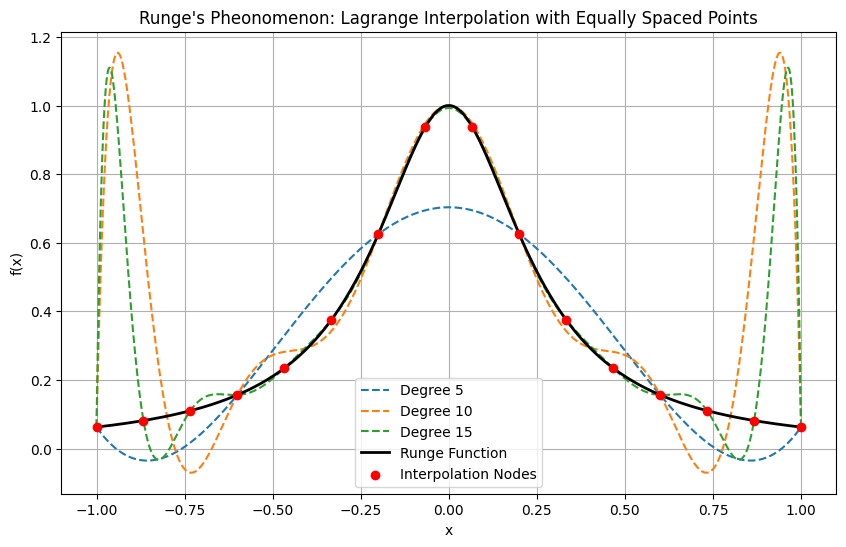

In [78]:
plt.figure(figsize=(10, 6))
for n in degrees:
  # Equally spaced interpolation nodes
  x_nodes = np.linspace(-1, 1, n+1)
  y_nodes = runge_function(x_nodes)
  # Compute Interpolation
  y_interp = lagrange_interpolation(x_nodes, y_nodes, x_true)
  # Plot results
  plt.plot(x_true, y_interp, label=f'Degree {n}', linestyle='--')
# Plot the true function
plt.plot(x_true, y_true, 'k', label='Runge Function', linewidth=2)
# Plot interpolation nodes for highest degree
plt.scatter(x_nodes, y_nodes, color='red', zorder=3, label='Interpolation Nodes')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title("Runge's Pheonomenon: Lagrange Interpolation with Equally Spaced Points")
plt.legend()
plt.grid(True)
plt.show()

## Fixing Runge's Phenomenon with Chebyshev Nodes

In [79]:
def chebyshev_nodes(n):
  """Generate Chebyshev nodes between -1 and 1"""
  return np.cos((2 * np.arange(1, n+2) - 1) / (2 * (n+1)) * np.pi)

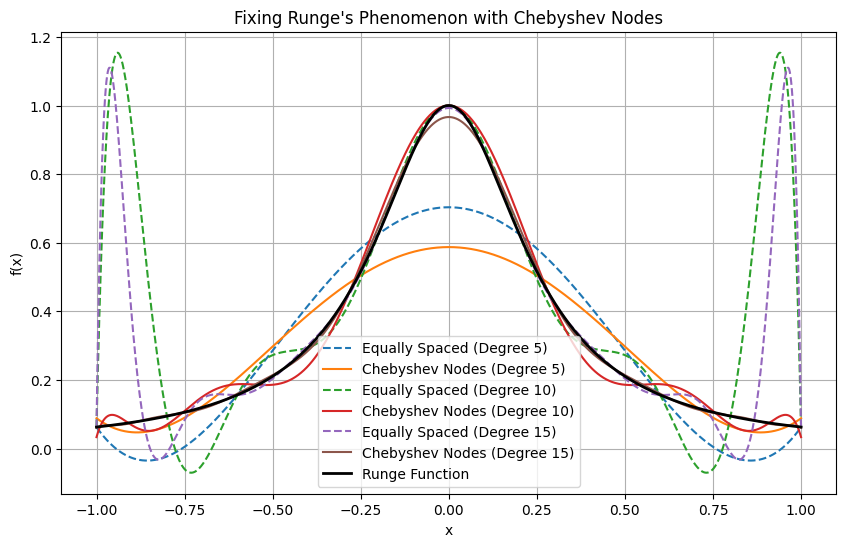

In [80]:
plt.figure(figsize=(10, 6))
for n in degrees:
  # Equally spaced nodes
  x_nodes_eq = np.linspace(-1, 1, n+1)
  y_nodes_eq = runge_function(x_nodes_eq)
  y_interp_eq = lagrange_interpolation(x_nodes_eq, y_nodes_eq, x_true)
  # Chebyshev Nodes
  x_nodes_cheb = chebyshev_nodes(n)
  y_nodes_cheb = runge_function(x_nodes_cheb)
  y_interp_cheb = lagrange_interpolation(x_nodes_cheb, y_nodes_cheb, x_true)
  # Plot for equally spaced nodes (dashed)
  plt.plot(x_true, y_interp_eq, label=f'Equally Spaced (Degree {n})', linestyle='--')
  # Plot for Chebyshev nodes (solid)
  plt.plot(x_true, y_interp_cheb, label=f'Chebyshev Nodes (Degree {n})', linestyle='-')
plt.plot(x_true, y_true, 'k', label='Runge Function', linewidth=2)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title("Fixing Runge's Phenomenon with Chebyshev Nodes")
plt.legend()
plt.grid(True)
plt.show()